In [1]:
import quarters_clean

In [3]:
reserves_df = quarters_clean.pd.read_parquet("../data/clean_foreign_exchange_reserves.parquet")

In [4]:
reserves_df

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,...,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Month,Quarter
0,NaN,NaN,NaN,0.42,NaN,2.00,0.09,NaN,0.22,NaN,...,NaN,NaN,NaN,NaN,21.28,NaN,0.00,1960,Apr,2
1,NaN,NaN,NaN,0.33,NaN,2.12,0.09,NaN,0.18,NaN,...,NaN,NaN,NaN,NaN,19.17,NaN,0.00,1961,Apr,2
2,NaN,NaN,NaN,0.42,NaN,1.93,0.01,NaN,0.16,NaN,...,NaN,NaN,NaN,NaN,18.19,NaN,0.00,1962,Apr,2
3,NaN,NaN,NaN,0.34,NaN,2.62,0.08,NaN,0.13,NaN,...,NaN,NaN,NaN,NaN,17.14,NaN,0.00,1963,Apr,2
4,NaN,NaN,NaN,0.08,NaN,2.52,0.07,NaN,0.16,NaN,...,NaN,NaN,NaN,NaN,16.90,NaN,0.00,1964,Apr,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
782,61.56,24.39,27.52,356.61,60.78,90.16,37.82,3281.21,56.99,18.31,...,517.48,938.00,7949.35,79.68,138.96,208.20,8.95,2020,Sep,3
783,82.14,28.58,35.26,368.89,63.49,106.27,53.31,3373.02,58.73,24.35,...,546.08,1007.56,8293.60,121.26,250.08,229.94,9.75,2021,Sep,3
784,83.58,32.28,39.68,327.58,72.27,102.69,37.78,3193.58,56.34,26.26,...,681.21,872.75,7561.94,107.04,230.15,192.22,9.44,2022,Sep,3
785,90.41,28.41,36.48,340.32,72.84,112.45,41.40,3308.47,57.60,2.85,...,634.48,747.86,7736.51,122.20,240.99,203.29,9.99,2023,Sep,3


In [5]:
quarters_clean.summarize_missing_by_country(reserves_df)

,Missing Count,Missing %
Belgium,637,80.94
France,628,79.80
Estonia,613,77.89
Latvia,565,71.79
Romania,543,69.00
Macedonia,541,68.74
Greece,529,67.22
Serbia,529,67.22
Sweden,518,65.82
Ireland,517,65.69


**H1)** The previous output indicates that Belfium will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [6]:
reserves_df = reserves_df.drop(columns=["Month"])

In [7]:
missing_entries = quarters_clean.get_missing_entries(reserves_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1,1960,Australia,NaN
1,1,1960,Australia,NaN
2,1,1960,Australia,NaN
3,1,1960,Austria,NaN
4,1,1960,Austria,NaN


In [8]:
belgium_missing = quarters_clean.clean_country_missing_entries(missing_entries, "Belgium")
belgium_missing

,Quarter,Year,Country,Value
0,1,1960,Belgium,NaN
1,1,1960,Belgium,NaN
2,1,1960,Belgium,NaN
3,2,1960,Belgium,NaN
4,2,1960,Belgium,NaN
...,...,...,...,...
632,3,2012,Belgium,NaN
633,4,2012,Belgium,NaN
634,4,2012,Belgium,NaN
635,4,2012,Belgium,NaN


The previous outputs show us that Belgium has no values for the unemployment rate index from 1960 to 2012 nor 2025. Consequently, it has values in the range from 2013 to 2024, a desirable range since other values which we extracted with the crawlers are defined between 2014 and 2023.

### Let's delete all the data from the beginning until 2012 and 2025

In [9]:
clean_df1 = reserves_df.copy()

In [10]:
clean_df1 = quarters_clean.filter_by_year(clean_df1, min_year=2012, max_year=2024)
clean_df1

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
0,49.85,19.16,21.83,378.67,29.06,70.21,41.23,3563.31,40.09,12.06,...,37.77,440.65,488.85,5232.63,133.99,146.80,126.66,5.91,2013,2
1,62.13,18.08,19.85,366.72,27.50,76.45,40.28,4006.61,44.65,11.68,...,33.96,424.07,483.22,5459.69,129.73,144.28,133.59,6.20,2014,2
2,62.48,21.95,22.39,364.47,38.07,77.68,38.82,3773.28,47.18,14.74,...,49.36,513.53,565.05,5295.79,122.86,121.29,151.48,7.07,2015,2
3,58.66,22.88,22.02,362.20,42.31,83.92,39.87,3316.14,47.30,13.22,...,49.83,490.68,635.26,6239.18,116.03,121.04,173.07,6.83,2016,2
4,75.33,21.49,22.74,374.95,46.22,84.71,38.96,3124.57,46.94,14.41,...,59.31,532.13,744.38,6386.35,102.71,120.03,172.75,7.81,2017,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,61.56,24.39,27.52,356.61,60.78,90.16,37.82,3281.21,56.99,18.31,...,68.36,517.48,938.00,7949.35,79.68,138.96,208.20,8.95,2020,3
140,82.14,28.58,35.26,368.89,63.49,106.27,53.31,3373.02,58.73,24.35,...,78.68,546.08,1007.56,8293.60,121.26,250.08,229.94,9.75,2021,3
141,83.58,32.28,39.68,327.58,72.27,102.69,37.78,3193.58,56.34,26.26,...,90.25,681.21,872.75,7561.94,107.04,230.15,192.22,9.44,2022,3
142,90.41,28.41,36.48,340.32,72.84,112.45,41.40,3308.47,57.60,2.85,...,92.67,634.48,747.86,7736.51,122.20,240.99,203.29,9.99,2023,3


In [11]:
clean_df1 = clean_df1.sort_values(by=['Year', 'Quarter'])
clean_df1

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
36,43.74,19.93,22.63,373.74,27.22,68.89,39.33,3424.32,38.54,11.13,...,38.84,433.26,486.68,5341.75,123.20,148.84,125.06,5.69,2013,1
48,46.45,20.20,22.83,373.42,27.75,68.55,39.95,3439.91,37.87,11.08,...,38.18,410.05,487.34,5413.80,124.20,151.90,130.84,5.59,2013,1
84,48.74,20.46,22.96,376.93,28.34,69.36,39.83,3471.41,39.34,11.28,...,39.66,428.55,496.14,5209.98,126.69,146.33,128.50,5.80,2013,1
0,49.85,19.16,21.83,378.67,29.06,70.21,41.23,3563.31,40.09,12.06,...,37.77,440.65,488.85,5232.63,133.99,146.80,126.66,5.91,2013,2
72,51.86,17.34,20.50,369.40,28.54,70.70,41.00,3525.03,40.82,12.02,...,35.43,436.52,479.35,5319.48,122.57,145.71,125.44,5.76,2013,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,94.39,31.49,39.47,363.28,71.75,124.21,45.50,3495.34,61.91,2.98,...,98.19,665.40,787.60,8264.44,147.85,245.22,222.26,10.36,2024,3
143,93.97,32.78,38.21,372.02,81.70,128.07,45.63,3571.80,63.61,2.93,...,98.56,663.60,802.29,7887.67,152.07,250.62,226.85,9.88,2024,3
35,102.34,34.07,39.88,329.73,82.25,121.62,44.42,3455.56,NaN,NaN,...,103.72,700.60,822.57,8091.30,155.16,238.80,219.12,9.87,2024,4
119,98.41,34.12,39.86,363.00,77.78,122.61,44.91,3521.64,NaN,NaN,...,103.42,669.13,815.53,8140.57,157.74,241.46,222.80,9.74,2024,4


In [12]:
clean_df1 = clean_df1.reset_index(drop=True)
clean_df1

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,Croatia,...,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay,Year,Quarter
0,43.74,19.93,22.63,373.74,27.22,68.89,39.33,3424.32,38.54,11.13,...,38.84,433.26,486.68,5341.75,123.20,148.84,125.06,5.69,2013,1
1,46.45,20.20,22.83,373.42,27.75,68.55,39.95,3439.91,37.87,11.08,...,38.18,410.05,487.34,5413.80,124.20,151.90,130.84,5.59,2013,1
2,48.74,20.46,22.96,376.93,28.34,69.36,39.83,3471.41,39.34,11.28,...,39.66,428.55,496.14,5209.98,126.69,146.33,128.50,5.80,2013,1
3,49.85,19.16,21.83,378.67,29.06,70.21,41.23,3563.31,40.09,12.06,...,37.77,440.65,488.85,5232.63,133.99,146.80,126.66,5.91,2013,2
4,51.86,17.34,20.50,369.40,28.54,70.70,41.00,3525.03,40.82,12.02,...,35.43,436.52,479.35,5319.48,122.57,145.71,125.44,5.76,2013,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,94.39,31.49,39.47,363.28,71.75,124.21,45.50,3495.34,61.91,2.98,...,98.19,665.40,787.60,8264.44,147.85,245.22,222.26,10.36,2024,3
140,93.97,32.78,38.21,372.02,81.70,128.07,45.63,3571.80,63.61,2.93,...,98.56,663.60,802.29,7887.67,152.07,250.62,226.85,9.88,2024,3
141,102.34,34.07,39.88,329.73,82.25,121.62,44.42,3455.56,NaN,NaN,...,103.72,700.60,822.57,8091.30,155.16,238.80,219.12,9.87,2024,4
142,98.41,34.12,39.86,363.00,77.78,122.61,44.91,3521.64,NaN,NaN,...,103.42,669.13,815.53,8140.57,157.74,241.46,222.80,9.74,2024,4


In [14]:
quarters_clean.summarize_missing_by_country(clean_df1).head(7)

,Missing Count,Missing %
Finland,16,11.11
Portugal,15,10.42
Colombia,3,2.08
Croatia,3,2.08
New-Zealand,1,0.69
Brazil,1,0.69
South-Korea,1,0.69


In [16]:
clean_df1["Finland"] = clean_df1["Finland"].ffill()
clean_df1["Portugal"] = clean_df1["Portugal"].ffill()
clean_df1["Colombia"] = clean_df1["Colombia"].ffill()
clean_df1["Croatia"] = clean_df1["Croatia"].ffill()
clean_df1["New-Zealand"] = clean_df1["New-Zealand"].ffill()
clean_df1["Brazil"] = clean_df1["Brazil"].ffill()
clean_df1["South-Korea"] = clean_df1["South-Korea"].ffill()

In [17]:
quarters_clean.summarize_missing_by_country(clean_df1).head(7)

,Missing Count,Missing %
Australia,0,0.0
Austria,0,0.0
Belgium,0,0.0
Brazil,0,0.0
Bulgaria,0,0.0
Canada,0,0.0
Chile,0,0.0


In [18]:
clean_df1 = quarters_clean.average_by_year(clean_df1)

   Year  Australia    Austria    Belgium      Brazil   Bulgaria     Canada  \
0  2013  52.751667  18.548333  21.270000  369.993333  28.490833  70.238333   
1  2014  60.172500  19.199167  20.267500  370.233333  28.982500  75.182500   
2  2015  62.596667  21.557500  22.300000  363.278333  37.627500  77.010833   
3  2016  60.568333  22.639167  22.410833  364.315833  43.515833  82.921667   
4  2017  73.416667  19.765833  22.252500  376.241667  46.143333  84.630833   

       Chile        China   Colombia  ...  South-Africa  South-Korea  \
0  40.530000  3603.890833  41.185833  ...    480.495000   333.290000   
1  40.345833  3948.181667  45.771667  ...    535.531667   360.684167   
2  38.555000  3681.067500  46.904167  ...    599.556667   368.030000   
3  39.422500  3259.304167  47.028333  ...    678.905000   371.585833   
4  38.881667  3161.476667  47.280000  ...    633.533333   381.091667   

       Spain      Sweden  Switzerland     Thailand      Turkey         USA  \
0  36.449167  428.70

In [19]:
clean_df1

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
0,2013,52.751667,18.548333,21.270000,369.993333,28.490833,70.238333,40.530000,3603.890833,41.185833,...,480.495000,333.290000,36.449167,428.700833,484.984167,5354.420833,128.744167,146.778333,129.022500,5.810833
1,2014,60.172500,19.199167,20.267500,370.233333,28.982500,75.182500,40.345833,3948.181667,45.771667,...,535.531667,360.684167,35.978333,442.709167,497.542500,5370.804167,130.288333,140.770833,134.969167,6.500833
2,2015,62.596667,21.557500,22.300000,363.278333,37.627500,77.010833,38.555000,3681.067500,46.904167,...,599.556667,368.030000,49.233333,499.746667,574.105833,5411.827500,120.839167,120.473333,149.983333,6.701667
3,2016,60.568333,22.639167,22.410833,364.315833,43.515833,82.921667,39.422500,3259.304167,47.028333,...,678.905000,371.585833,54.914167,514.412500,656.758333,6182.182500,115.998333,119.524167,166.655833,6.731667
4,2017,73.416667,19.765833,22.252500,376.241667,46.143333,84.630833,38.881667,3161.476667,47.280000,...,633.533333,381.091667,58.115000,519.379167,752.208333,6442.580833,109.052500,121.787500,175.003333,7.841667
5,2018,71.986667,20.140000,22.384167,379.267500,45.754167,82.756667,37.931667,3201.767500,47.660000,...,668.790000,400.084167,58.914167,536.202500,788.340000,6733.004167,100.197500,124.729167,188.556667,8.271667
6,2019,73.037500,21.502500,25.073333,377.925000,48.742500,85.416667,39.061667,3206.211667,52.034167,...,744.015000,404.584167,65.325833,550.795000,816.900000,6699.540833,99.563333,127.595833,194.944167,7.959167
7,2020,65.861667,24.295000,27.550833,352.696667,54.590833,88.800833,37.432500,3262.677500,55.978333,...,893.277500,416.920833,68.095000,523.429167,892.870000,7610.353333,90.010000,135.418333,208.609167,8.899167
8,2021,68.871667,26.110000,30.481667,359.058333,58.371667,94.895833,47.328333,3366.054167,58.872500,...,827.308333,456.841667,71.934167,509.424167,987.581667,7982.624167,105.070833,187.279167,218.990833,9.987500
9,2022,81.175833,31.935833,38.776667,341.515833,66.012500,105.453333,44.143333,3293.893333,57.351667,...,971.085833,438.766667,86.178333,621.454167,937.484167,7815.097500,109.914167,240.817500,212.458333,9.538333


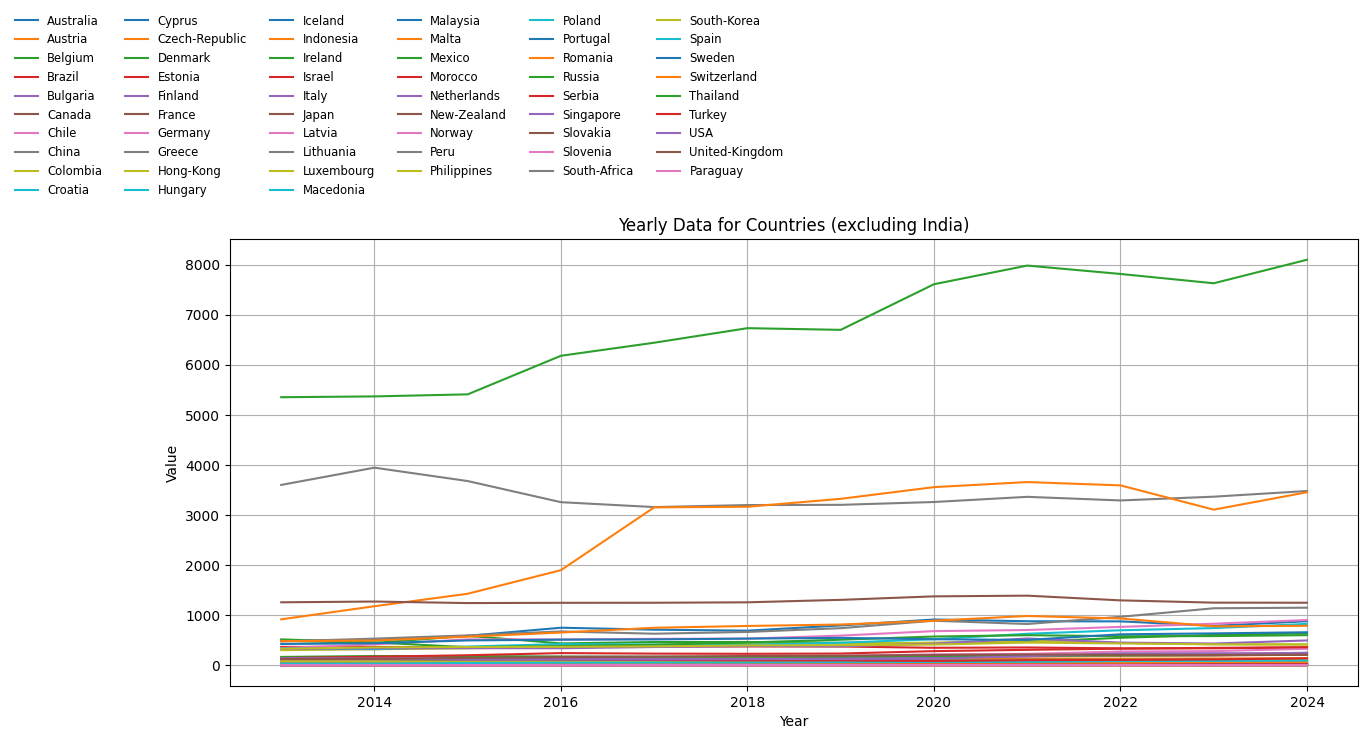

In [22]:
quarters_clean.plot_countries(clean_df1, exclude_country='India', legend_columns=6)

In [24]:
clean_df1.to_parquet("../data/clean_foreign_exchange_reserves.parquet", index=False)